# 05  Python Modeling and Evaluation

# Install scikit-learn And import all libraries 

In [7]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, precision_recall_curve)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve


# Load the Data

In [22]:
SEED = 42
DATA = "C:/Users/Siddhesh/Downloads/bank-customer-churn/data/raw/bank_churn.csv"
OUT  = "C:/Users/Siddhesh/Downloads/bank-customer-churn/data/processed/scored_customers.csv"
pd.set_option("display.width", 140)     
raw = pd.read_csv(DATA)
raw.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
print("shape:", raw.shape)
print("missing values per column:\n", raw.isna().sum()[raw.isna().sum() > 0])
assert raw["CustomerId"].is_unique,"Duplicate CustomerId found: investigate before modeling"
churn_rate = raw["Exited"].mean()
print(f"churn rate: {churn_rate:.3f}")

shape: (10000, 14)
missing values per column:
 Series([], dtype: int64)
churn rate: 0.204


In [5]:
majority_accuracy = 1 - churn_rate
print(f"'Nobody churns' accuracy: {majority_accuracy:.3f}  (and it catches 0 churners)")

'Nobody churns' accuracy: 0.796  (and it catches 0 churners)


# Drop columns

In [6]:
y   = raw["Exited"].astype(int)
ids = raw["CustomerId"]
df  = raw.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
print(df.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


# Create new columns from raw data

In [7]:
df["HasZeroBalance"] = (df["Balance"] == 0).astype(int)
df["BalanceToSalary"] =  df["Balance"] / df["EstimatedSalary"].replace(0, np.nan)
df["AgeBand"] = pd.cut(df["Age"], bins=[0, 30, 40, 50, 60, 70, 80], 
                       labels=["<30", "30-39", "40-49", "50-59", "60-69", "70+"])
df["ProductGroup"] = df["NumOfProducts"].clip(upper=3).astype(str).replace({"3": "3+"})
df["Tenureyoungest"] = (df["Tenure"] <= 1).astype(int)
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,HasZeroBalance,BalanceToSalary,AgeBand,ProductGroup,Tenureyoungest
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.000000,40-49,1,0
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0.744677,40-49,1,1
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,0,1.401375,40-49,3+,0
3,699,France,Female,39,1,0.00,2,0,0,93826.63,1,0.000000,30-39,2,1
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1.587055,40-49,1,0


# Split Data using train test splits

In [8]:
X_tr, X_te, Y_tr, Y_te = train_test_split (df, y, test_size=0.2, stratify =y, random_state=SEED)
print("train shape:", X_tr.shape, "test shape:", X_te.shape)
print(f"train churn rate: {Y_tr.mean():.3f}, test churn rate: {Y_te.mean():.3f}")

train shape: (8000, 15) test shape: (2000, 15)
train churn rate: 0.204, test churn rate: 0.203


In [9]:
def build_models(num, cat):
    def prep(scale):
        steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
        return ColumnTransformer([("num", Pipeline(steps), num),
                                  ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return {
        "Baseline (majority)": Pipeline([("p", prep(False)), ("m", DummyClassifier(strategy="prior"))]),
        "LogReg": Pipeline([("p", prep(True)),
                            ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "RandomForest": Pipeline([("p", prep(False)),
                                  ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                        class_weight="balanced", n_jobs=-1, random_state=SEED))]),
        "HistGB": Pipeline([("p", prep(False)),
                            ("m", HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05,
                                  max_iter=300, class_weight="balanced", random_state=SEED))]),
    }

num = X_tr.select_dtypes("number").columns.tolist()
cat = X_tr.select_dtypes(exclude="number").columns.tolist()
models = build_models(num, cat)
print("numeric:", num); print("categorical:", cat)

numeric: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'HasZeroBalance', 'BalanceToSalary', 'Tenureyoungest']
categorical: ['Geography', 'Gender', 'AgeBand', 'ProductGroup']


In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []                                   # outside the loop, no indent

for name, pipe in models.items():
    s = cross_validate(pipe, X_tr, Y_tr, cv=cv,
                       scoring=["roc_auc", "average_precision", "recall", "precision"])
    rows.append({"model": name,             # inside the loop, indented
                 **{k: round(s[f"test_{k}"].mean(), 3) for k in ["roc_auc", "average_precision", "recall", "precision"]},
                 "pr_auc_std": round(s["test_average_precision"].std(), 3)})

cmp_df = pd.DataFrame(rows).set_index("model")   # outside the loop, no indent
cmp_df

C:\Users\Siddhesh\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Siddhesh\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Siddhesh\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", res

,roc_auc,average_precision,recall,precision,pr_auc_std
model,,,,,
Baseline (majority),0.500,0.204,0.000,0.000,0.000
LogReg,0.845,0.657,0.745,0.471,0.016
RandomForest,0.859,0.685,0.710,0.524,0.022
HistGB,0.862,0.699,0.728,0.522,0.022


# Pick the best model and choose thresold

Best model by CV PR-AUC: HistGB
Threshold chosen on training out-of-fold predictions: 0.581


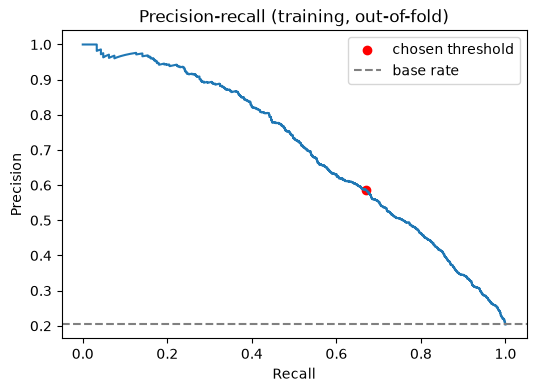

In [11]:
best_name = cmp_df.drop("Baseline (majority)")["average_precision"].idxmax()
best = models[best_name]
print("Best model by CV PR-AUC:", best_name)

oof = cross_val_predict(best, X_tr, Y_tr, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(Y_tr, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
threshold = float(thr[f1s.argmax()])
print(f"Threshold chosen on training out-of-fold predictions: {threshold:.3f}")

plt.figure(figsize=(6, 4)); plt.plot(rec, prec); plt.scatter(rec[:-1][f1s.argmax()], prec[:-1][f1s.argmax()], c="red", label="chosen threshold")
plt.axhline(Y_tr.mean(), ls="--", c="grey", label="base rate"); plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-recall (training, out-of-fold)"); plt.legend(); plt.show()

In [12]:
best.fit(X_tr, Y_tr)
p    = best.predict_proba(X_te)[:, 1]
pred = (p >= threshold).astype(int)

print(f"ROC-AUC  {roc_auc_score(Y_te, p):.3f}")
print(f"PR-AUC   {average_precision_score(Y_te, p):.3f}   (base rate = {Y_te.mean():.3f})")
print(f"Precision {precision_score(Y_te, pred):.3f} | Recall {recall_score(Y_te, pred):.3f} | F1 {f1_score(Y_te, pred):.3f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:\n", confusion_matrix(Y_te, pred))

ROC-AUC  0.869
PR-AUC   0.719   (base rate = 0.203)
Precision 0.586 | Recall 0.688 | F1 0.633
Confusion matrix [[TN, FP], [FN, TP]]:
 [[1395  198]
 [ 127  280]]


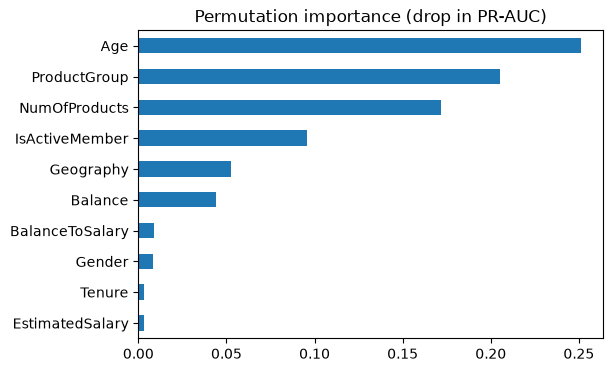

In [13]:
pi  = permutation_importance(best, X_te, Y_te, scoring="average_precision", n_repeats=10, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
imp.tail(10).plot(kind="barh", figsize=(6, 4), title="Permutation importance (drop in PR-AUC)"); plt.show()

,customers,churners,cum_gain,lift
decile,,,,
1,200,169,0.415,4.152
2,200,86,0.627,2.113
3,200,51,0.752,1.253
4,200,33,0.833,0.811
5,200,23,0.889,0.565
6,200,21,0.941,0.516
7,200,7,0.958,0.172
8,200,8,0.978,0.197
9,200,5,0.990,0.123


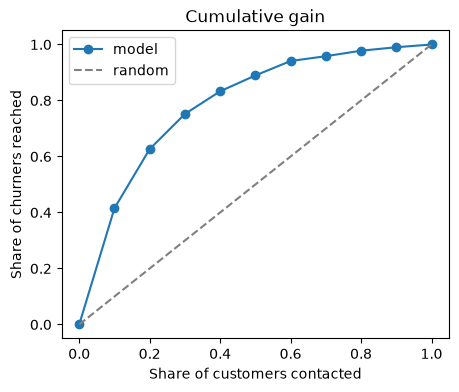

In [14]:
t = pd.DataFrame({"p": p, "y": Y_te.values}).sort_values("p", ascending=False).reset_index(drop=True)
t["decile"] = pd.qcut(t.index, 10, labels=range(1, 11))
g = t.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"))
g["cum_gain"] = (g["churners"] / g["churners"].sum()).cumsum()
g["lift"]     = (g["churners"] / g["customers"]) / t["y"].mean()
display(g.round(3))

x = np.arange(0, 11) / 10; plt.figure(figsize=(5, 4))
plt.plot(x, np.r_[0, g["cum_gain"].values], marker="o", label="model"); plt.plot(x, x, "--", c="grey", label="random")
plt.xlabel("Share of customers contacted"); plt.ylabel("Share of churners reached"); plt.title("Cumulative gain"); plt.legend(); plt.show()

,mean_predicted,observed_rate
0,0.031,0.020
1,0.069,0.025
2,0.116,0.040
3,0.172,0.035
4,0.235,0.105
5,0.320,0.115
6,0.426,0.165
7,0.566,0.255
8,0.735,0.430
9,0.929,0.845


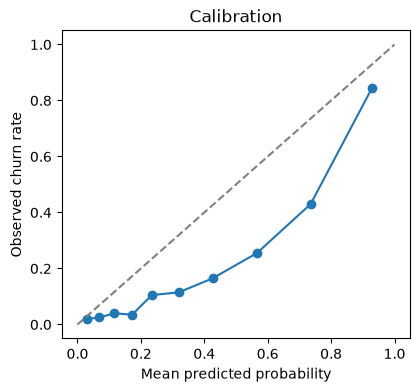

In [16]:
frac_pos, mean_pred = calibration_curve(Y_te, p, n_bins=10, strategy="quantile")
display(pd.DataFrame({"mean_predicted": mean_pred, "observed_rate": frac_pos}).round(3))
plt.figure(figsize=(4.5, 4)); plt.plot(mean_pred, frac_pos, marker="o"); plt.plot([0, 1], [0, 1], "--", c="grey")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed churn rate"); plt.title("Calibration"); plt.show()

In [17]:
def net_benefit(th, probs, y_true, value_saved, cost_contact, save_rate):
    contact = probs >= th
    return (contact & (y_true == 1)).sum() * save_rate * value_saved - contact.sum() * cost_contact

ths = np.linspace(0.05, 0.95, 91)
rows = []
for save_rate in [0.10, 0.25, 0.40]:
    for cost in [15, 25, 40]:
        value = 400                                                        # assumed value of a saved customer
        nb_train = [net_benefit(t_, oof, Y_tr.values, value, cost, save_rate) for t_ in ths]
        th_best = ths[int(np.argmax(nb_train))]                           # chosen on training OOF only
        nb_test = net_benefit(th_best, p, Y_te.values, value, cost, save_rate) / len(Y_te) * 1000
        rows.append({"save_rate": save_rate, "contact_cost": cost, "chosen_threshold": round(th_best, 2),
                     "net_benefit_per_1000_customers (holdout, ASSUMPTION-BASED)": round(nb_test)})
display(pd.DataFrame(rows))

,save_rate,contact_cost,chosen_threshold,"net_benefit_per_1000_customers (holdout, ASSUMPTION-BASED)"
0,0.10,15,0.72,2072
1,0.10,25,0.85,920
2,0.10,40,0.95,-100
3,0.25,15,0.36,10952
4,0.25,25,0.58,8012
5,0.25,40,0.72,4780
6,0.40,15,0.23,21545
7,0.40,25,0.37,17073
8,0.40,40,0.58,12820


In [23]:
scored = pd.concat([
    X_tr.assign(churn_probability=oof, actual_churn=Y_tr, split="train (out-of-fold)"),
    X_te.assign(churn_probability=p,   actual_churn=Y_te, split="test (holdout)")])
scored["CustomerId"]      = ids.loc[scored.index]
scored["predicted_churn"] = (scored["churn_probability"] >= threshold).astype(int)
scored["risk_band"]       = pd.cut(scored["churn_probability"], [-.01, .3, .6, 1.0], labels=["Low", "Medium", "High"])
scored.sort_index().to_csv(OUT, index=False)
print("Exported", len(scored), "customers to", OUT)

Exported 10000 customers to C:/Users/Siddhesh/Downloads/bank-customer-churn/data/processed/scored_customers.csv
